In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [2]:
# Step 2: Load the engineered dataset
df_cluster = pd.read_csv(
    "../dataset/market_features_engineered.csv"
)
print("Engineered Dataset Loaded Successfully!")
print("\nDataset Shape:", df_cluster.shape)
print("\nColumn Names:")
print(df_cluster.columns.tolist())
print("\nFirst 5 Records:")
display(df_cluster.head())

Engineered Dataset Loaded Successfully!

Dataset Shape: (14330, 13)

Column Names:
['state', 'district', 'market', 'commodity', 'avg_price', 'median_price', 'std_price', 'min_price', 'max_price', 'avg_arrival', 'median_arrival', 'total_arrival', 'total_records']

First 5 Records:


,state,district,market,commodity,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
0,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Black Gram(Urd Beans)(Whole),9.159152,9.159152,0.000000,9.159152,9.159152,0.255347,0.223144,2.360854,33
1,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Green Gram(Moong)(Whole),9.159152,9.159152,0.000000,9.159152,9.159152,0.328868,0.300105,2.628285,33
2,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Tomato,8.335112,8.160804,7.507156,7.601402,8.853808,0.644774,0.530628,2.213754,9
3,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Turmeric,10.119372,10.126671,6.270317,10.043293,10.126671,0.377398,0.262364,2.780681,33
4,Andaman and Nicobar,North and Middle Andaman,Mayabander Vegetable Market,Tomato,8.909370,8.987322,6.797301,8.699681,8.987322,0.048790,0.048790,0.223144,5


In [3]:
# Step 3: Separate market information and numerical features
market_info = df_cluster[
    ['state', 'district', 'market', 'commodity']
].copy()
X = df_cluster.drop(
    columns=['state', 'district', 'market', 'commodity']
)
clustering_features = X.columns.tolist()
print("Market Information Shape:", market_info.shape)
print("Numerical Features Shape:", X.shape)
print("\nSelected Clustering Features:")
print(clustering_features)
print("\nFirst 5 Numerical Records:")
display(X.head())

Market Information Shape: (14330, 4)
Numerical Features Shape: (14330, 9)

Selected Clustering Features:
['avg_price', 'median_price', 'std_price', 'min_price', 'max_price', 'avg_arrival', 'median_arrival', 'total_arrival', 'total_records']

First 5 Numerical Records:


,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
0,9.159152,9.159152,0.000000,9.159152,9.159152,0.255347,0.223144,2.360854,33
1,9.159152,9.159152,0.000000,9.159152,9.159152,0.328868,0.300105,2.628285,33
2,8.335112,8.160804,7.507156,7.601402,8.853808,0.644774,0.530628,2.213754,9
3,10.119372,10.126671,6.270317,10.043293,10.126671,0.377398,0.262364,2.780681,33
4,8.909370,8.987322,6.797301,8.699681,8.987322,0.048790,0.048790,0.223144,5


In [4]:
# Step 4: Check missing and infinite values
print("Missing Values:")
print(X.isnull().sum())
print("\nTotal Missing Values:", X.isnull().sum().sum())
print("\nInfinite Values:")
print(np.isinf(X).sum())
print("\nTotal Infinite Values:", np.isinf(X).sum().sum())

Missing Values:
avg_price         0
median_price      0
std_price         0
min_price         0
max_price         0
avg_arrival       0
median_arrival    0
total_arrival     0
total_records     0
dtype: int64

Total Missing Values: 0

Infinite Values:
avg_price         0
median_price      0
std_price         0
min_price         0
max_price         0
avg_arrival       0
median_arrival    0
total_arrival     0
total_records     0
dtype: int64

Total Infinite Values: 0


In [5]:
# Step 5: Feature Scaling using StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature Scaling Completed Successfully!")
print("\nOriginal Feature Shape:", X.shape)
print("Scaled Feature Shape:", X_scaled.shape)
print("\nFirst 5 Scaled Records:")
display(pd.DataFrame(
    X_scaled,
    columns=clustering_features
).head())

Feature Scaling Completed Successfully!

Original Feature Shape: (14330, 9)
Scaled Feature Shape: (14330, 9)

First 5 Scaled Records:


,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
0,1.485415,1.481177,-2.103968,1.633809,1.202495,-1.216895,-1.147742,-0.861485,0.812829
1,1.485415,1.481177,-2.103968,1.633809,1.202495,-1.178343,-1.104147,-0.759924,0.812829
2,0.279775,0.058569,1.033543,-0.397336,0.739765,-1.012695,-0.973565,-0.917348,-0.588078
3,2.890296,2.859854,0.516623,2.786638,2.668712,-1.152896,-1.125525,-0.702050,0.812829
4,1.119964,1.236325,0.736869,1.034707,0.942096,-1.325205,-1.246506,-1.673306,-0.821562


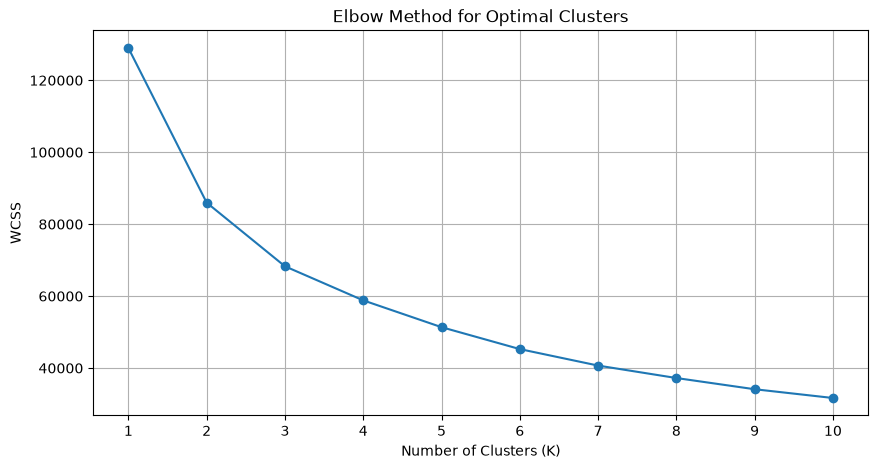

In [6]:
# Step 6: Elbow Method
wcss = []
for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

Clusters: 2, Silhouette Score: 0.3065
Clusters: 3, Silhouette Score: 0.2870
Clusters: 4, Silhouette Score: 0.2931
Clusters: 5, Silhouette Score: 0.2622
Clusters: 6, Silhouette Score: 0.2695
Clusters: 7, Silhouette Score: 0.2809
Clusters: 8, Silhouette Score: 0.2856
Clusters: 9, Silhouette Score: 0.2888
Clusters: 10, Silhouette Score: 0.2826


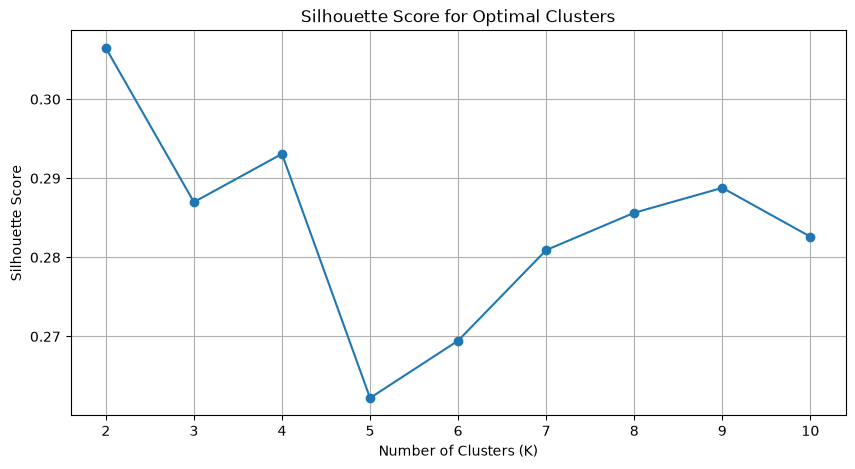

In [7]:
# Step 7: Calculate Silhouette Scores
silhouette_scores = []
for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

# Plot Silhouette Scores
plt.figure(figsize=(10, 5))
plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [8]:
# Step 8: Select optimal number of clusters
optimal_k = 2
print("Optimal Number of Clusters:", optimal_k)
print(
    "Best Silhouette Score:",
    max(silhouette_scores)
)
print("Cluster selection completed!")

Optimal Number of Clusters: 2
Best Silhouette Score: 0.3064682356381893
Cluster selection completed!


In [9]:
# Step 9: Train final K-Means model
kmeans_model = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)
cluster_labels = kmeans_model.fit_predict(X_scaled)
print("K-Means Model Trained Successfully!")
print("\nNumber of Clusters:", optimal_k)
print("Total Records Clustered:", len(cluster_labels))
print("\nFirst 10 Cluster Labels:")
print(cluster_labels[:10])

K-Means Model Trained Successfully!

Number of Clusters: 2
Total Records Clustered: 14330

First 10 Cluster Labels:
[1 1 1 1 1 0 1 1 0 1]


In [10]:
# Step 10: Add cluster labels to the dataset
clustered_data = df_cluster.copy()
clustered_data['cluster'] = cluster_labels
print("Cluster Labels Added Successfully!")
print("\nDataset Shape:", clustered_data.shape)
print("\nFirst 5 Clustered Records:")
display(clustered_data.head())

Cluster Labels Added Successfully!

Dataset Shape: (14330, 14)

First 5 Clustered Records:


,state,district,market,commodity,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records,cluster
0,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Black Gram(Urd Beans)(Whole),9.159152,9.159152,0.000000,9.159152,9.159152,0.255347,0.223144,2.360854,33,1
1,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Green Gram(Moong)(Whole),9.159152,9.159152,0.000000,9.159152,9.159152,0.328868,0.300105,2.628285,33,1
2,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Tomato,8.335112,8.160804,7.507156,7.601402,8.853808,0.644774,0.530628,2.213754,9,1
3,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Turmeric,10.119372,10.126671,6.270317,10.043293,10.126671,0.377398,0.262364,2.780681,33,1
4,Andaman and Nicobar,North and Middle Andaman,Mayabander Vegetable Market,Tomato,8.909370,8.987322,6.797301,8.699681,8.987322,0.048790,0.048790,0.223144,5,1


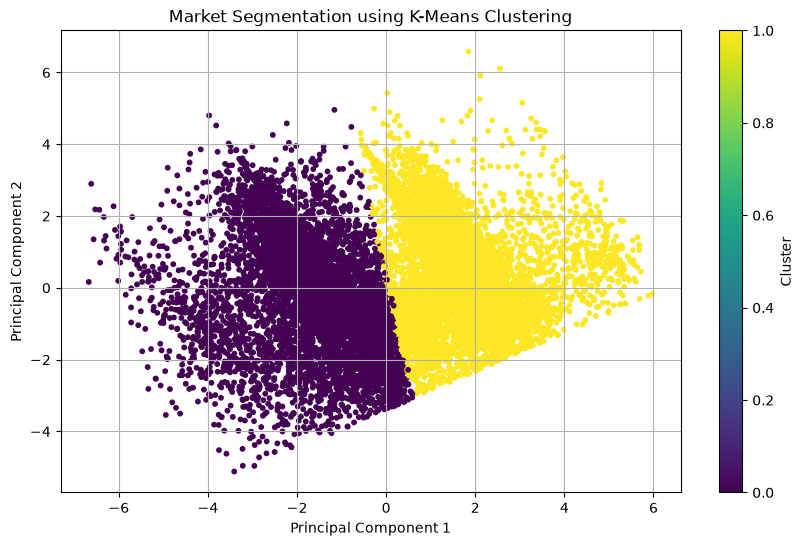

PCA Visualization Completed!
Explained Variance Ratio: [0.46904986 0.27117478]
Total Variance Explained: 74.02 %


In [11]:
# Step 11: Visualize clusters using PCA
from sklearn.decomposition import PCA
# Reduce 9 features to 2 principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create visualization
plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=cluster_labels,
    cmap='viridis',
    s=10
)
plt.title("Market Segmentation using K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(label="Cluster")
plt.grid(True)
plt.show()
print("PCA Visualization Completed!")
print(
    "Explained Variance Ratio:",
    pca.explained_variance_ratio_
)
print(
    "Total Variance Explained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

Number of Records in Each Cluster:
cluster
0    7377
1    6953
Name: count, dtype: int64


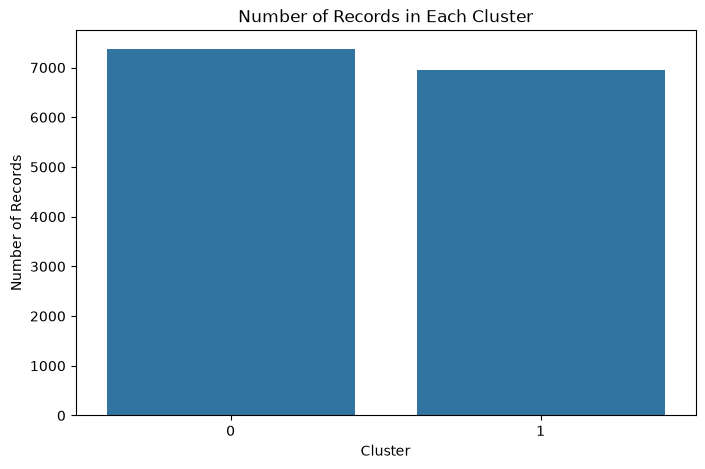

In [12]:
# Step 12: Analyze cluster sizes
cluster_counts = clustered_data['cluster'].value_counts().sort_index()

print("Number of Records in Each Cluster:")
print(cluster_counts)

# Visualize cluster sizes
plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)
plt.title("Number of Records in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Records")
plt.show()

In [13]:
# Step 13: Analyze cluster characteristics
cluster_summary = clustered_data.groupby('cluster')[
    clustering_features
].mean()
print("Cluster Characteristics:")
display(cluster_summary)

Cluster Characteristics:


,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
cluster,,,,,,,,,
0,7.591207,7.557888,4.611009,7.331064,7.846628,3.184171,2.837233,5.460707,20.673173
1,8.730273,8.715776,5.483170,8.516269,8.916336,1.930888,1.625555,3.747274,17.378973


In [14]:
# Step 14: Convert transformed features back to original scale
original_scale_data = clustered_data.copy()
log_features = [
    'avg_price',
    'median_price',
    'std_price',
    'min_price',
    'max_price',
    'avg_arrival',
    'median_arrival',
    'total_arrival'
]

for feature in log_features:
    original_scale_data[feature] = np.expm1(
        original_scale_data[feature]
    )

# Calculate cluster averages in original units
original_cluster_summary = original_scale_data.groupby(
    'cluster'
)[clustering_features].mean()
print("Cluster Characteristics in Original Scale:")
display(original_cluster_summary)

Cluster Characteristics in Original Scale:


,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records
cluster,,,,,,,,,
0,2106.565692,2052.435367,315.758028,1703.189410,2764.433102,222.395026,155.951204,3121.563274,20.673173
1,6678.919080,6615.988714,782.524270,5551.677561,8041.842930,27.716558,16.744185,615.476922,17.378973


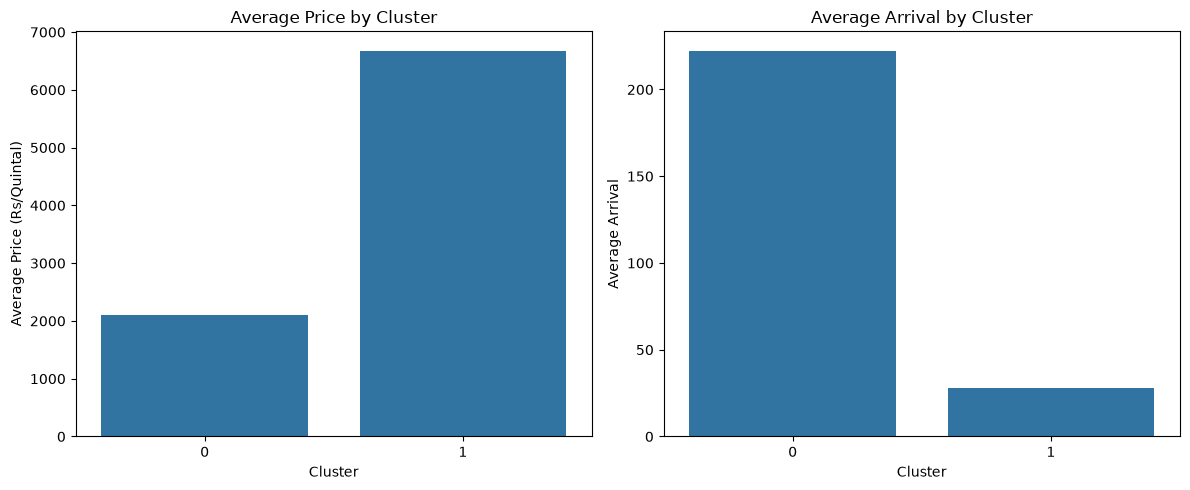

In [15]:
# Step 15: Visualize cluster characteristics
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Average price comparison
sns.barplot(
    x=original_cluster_summary.index,
    y=original_cluster_summary['avg_price'],
    ax=axes[0]
)
axes[0].set_title("Average Price by Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Average Price (Rs/Quintal)")
# Average arrival comparison
sns.barplot(
    x=original_cluster_summary.index,
    y=original_cluster_summary['avg_arrival'],
    ax=axes[1]
)
axes[1].set_title("Average Arrival by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Average Arrival")
plt.tight_layout()
plt.show()

In [16]:
# Step 16: Commodity-wise cluster analysis
commodity_cluster_summary = original_scale_data.groupby(
    ['commodity', 'cluster']
).agg(
    avg_price=('avg_price', 'mean'),
    avg_arrival=('avg_arrival', 'mean'),
    market_count=('market', 'nunique')
).reset_index()
print("Commodity-wise Cluster Analysis:")
display(commodity_cluster_summary.head(15))

Commodity-wise Cluster Analysis:


,commodity,cluster,avg_price,avg_arrival,market_count
0,Bajra(Pearl Millet/Cumbu),0,2209.329884,39.823582,505
1,Bajra(Pearl Millet/Cumbu),1,3443.622510,1.926558,30
2,Bengal Gram(Gram)(Whole),0,2606.250000,6.441667,4
3,Bengal Gram(Gram)(Whole),1,5592.350267,20.791372,814
4,Black Gram(Urd Beans)(Whole),1,7162.031869,15.408883,461
5,Cotton,0,1975.000000,11.400000,2
6,Cotton,1,7716.773698,80.389537,375
7,Cummin Seed(Jeera),1,18760.285981,27.258137,83
8,Dry Chillies,1,16175.616555,156.320576,50
9,Garlic,0,2752.982549,76.003541,17


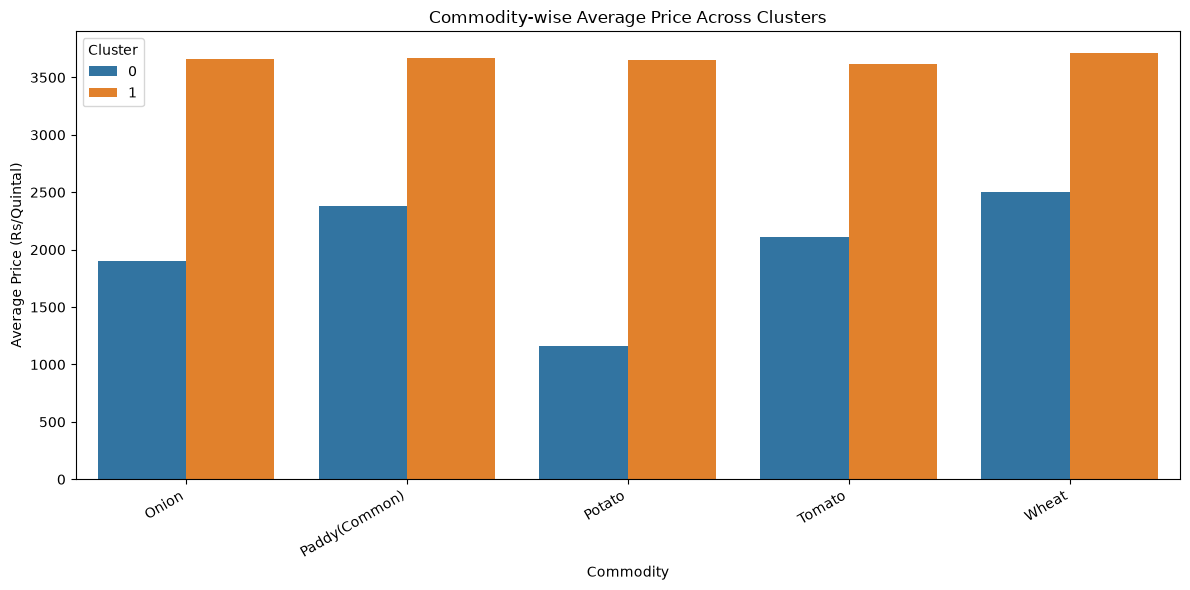

In [17]:
# Step 17: Visualize commodity-wise cluster prices
# Select top 5 commodities by number of records
top_commodities = (
    original_scale_data['commodity']
    .value_counts()
    .head(5)
    .index
)
# Filter commodity-wise cluster summary
top_commodity_data = commodity_cluster_summary[
    commodity_cluster_summary['commodity'].isin(top_commodities)
]
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_commodity_data,
    x='commodity',
    y='avg_price',
    hue='cluster'
)
plt.title("Commodity-wise Average Price Across Clusters")
plt.xlabel("Commodity")
plt.ylabel("Average Price (Rs/Quintal)")
plt.xticks(rotation=30, ha='right')
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

In [18]:
# Step 18: Save final clustering results
original_scale_data.to_csv(
    "../dataset/market_clusters.csv",
    index=False
)
print("Clustering Results Saved Successfully!")
print("\nSaved File: market_clusters.csv")
print("Dataset Shape:", original_scale_data.shape)
print("\nCluster Distribution:")
print(original_scale_data['cluster'].value_counts().sort_index())
print("\nFirst 5 Records:")
display(original_scale_data.head())

Clustering Results Saved Successfully!

Saved File: market_clusters.csv
Dataset Shape: (14330, 14)

Cluster Distribution:
cluster
0    7377
1    6953
Name: count, dtype: int64

First 5 Records:


,state,district,market,commodity,avg_price,median_price,std_price,min_price,max_price,avg_arrival,median_arrival,total_arrival,total_records,cluster
0,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Black Gram(Urd Beans)(Whole),9500.000000,9500.0,0.000000,9500.0,9500.0,0.290909,0.25,9.60,33,1
1,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Green Gram(Moong)(Whole),9500.000000,9500.0,0.000000,9500.0,9500.0,0.389394,0.35,12.85,33,1
2,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Tomato,4166.666667,3500.0,1820.027472,2000.0,7000.0,0.905556,0.70,8.15,9,1
3,Andaman and Nicobar,North and Middle Andaman,Diglipur Vegetable Market (Subhashgram),Turmeric,24818.181818,25000.0,527.644853,23000.0,25000.0,0.458485,0.30,15.13,33,1
4,Andaman and Nicobar,North and Middle Andaman,Mayabander Vegetable Market,Tomato,7400.000000,8000.0,894.427191,6000.0,8000.0,0.050000,0.05,0.25,5,1


In [19]:
# Step 19: Save trained model and scaler
import joblib
import os
# Create models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save K-Means model
joblib.dump(
    kmeans_model,
    "../models/kmeans_model.pkl"
)

# Save StandardScaler
joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

# Save PCA model
joblib.dump(
    pca,
    "../models/pca_model.pkl"
)

print("Model and Scaler Saved Successfully!")
print("\nSaved Files:")
print("1. models/kmeans_model.pkl")
print("2. models/scaler.pkl")
print("3. models/pca_model.pkl")

Model and Scaler Saved Successfully!

Saved Files:
1. models/kmeans_model.pkl
2. models/scaler.pkl
3. models/pca_model.pkl


In [20]:
# Verify saved model files

import joblib

loaded_kmeans = joblib.load("../models/kmeans_model.pkl")
loaded_scaler = joblib.load("../models/scaler.pkl")
loaded_pca = joblib.load("../models/pca_model.pkl")

print("All saved files loaded successfully!")

print("\nK-Means Model:", loaded_kmeans)
print("\nScaler:", loaded_scaler)
print("\nPCA Model:", loaded_pca)

All saved files loaded successfully!

K-Means Model: KMeans(n_clusters=2, n_init=10, random_state=42)

Scaler: StandardScaler()

PCA Model: PCA(n_components=2)


In [21]:
test_labels = loaded_kmeans.predict(X_scaled[:5])

print("Predicted Cluster Labels:", test_labels)
print("Original Cluster Labels:", cluster_labels[:5])

Predicted Cluster Labels: [1 1 1 1 1]
Original Cluster Labels: [1 1 1 1 1]
